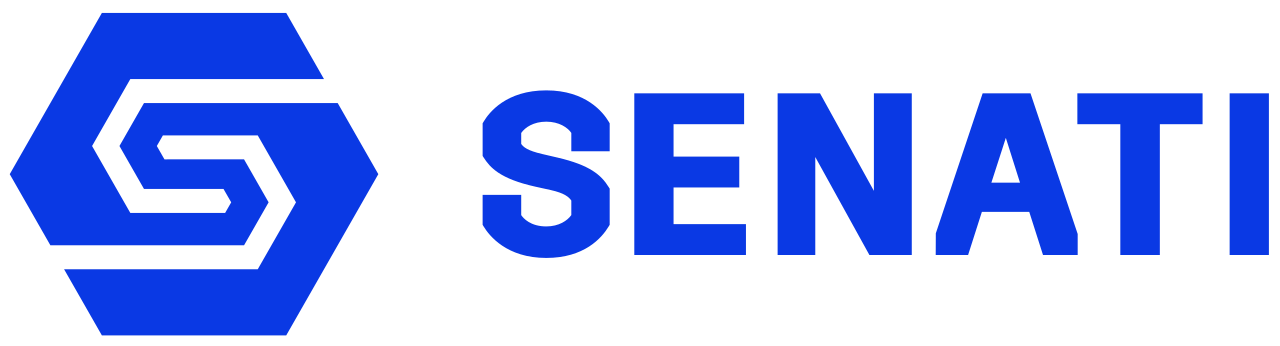

# Caso práctico para estudiantes — 01 RETO PAPELERIA

**Curso:** Machine Learning y Deep Learning  
**Modalidad:** Taller aplicado · **Nivel intermedio guiado**

**Instrucción para el taller:** lee cada explicación, ejecuta una celda y confirma qué cambió antes de continuar.

**Trabajo desarrollado por:** COCA CCORPA LORENA ABIGAIL  
**Institución:** SENATI · 2026  
**Actividad:** Reto 01 — Agrupación de clientes de papelería  
**Nota:** Los datos suministrados por el taller son simulados; los resultados y pruebas son cálculos realizados sobre esos CSV.

# Reto 01 — Agrupación de clientes de papelería
Una papelería cerca de un centro de estudios quiere conocer si existen comportamientos de compra diferentes. Cada fila contiene visitas del mes y gasto mensual.

**Trabajo:** usa Pandas, `StandardScaler` y K-Means con 3 grupos. Calcula el tamaño de cada grupo y explica los promedios por grupo. Después crea un formulario Flask con dos entradas. **No inventes que el grupo 0 es «mejor»: interpreta sus datos.**

## Guía para resolver sin perderse
Repite el procedimiento trabajado en el proyecto correspondiente: leer CSV → seleccionar `X` → escalar → entrenar → contar resultados → guardar `modelo_entrenado.joblib` → formulario Flask.

Este reto es **para desarrollar**: el cuaderno contiene apoyos y espacios incompletos, no la solución final.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto guiado original, paso por paso. Se conserva el enunciado original y el código se ejecuta en orden.</div>

In [1]:
# 1. Leer CSV. Completa el código.
import pandas as pd
datos = pd.read_csv('datos.csv')
print(datos.head())

  cliente  visitas_mes  gasto_mes_soles
0    P001           12            74.21
1    P002            4            54.62
2    P003           13           122.99
3    P004           16           267.19
4    P005           11            87.99


**Columnas a utilizar:** `['visitas_mes', 'gasto_mes_soles']`. Recuerda no incluir la columna que identifica cada registro.

In [2]:
# 2. Separar características y escalar
from sklearn.preprocessing import StandardScaler
COLUMNAS = ['visitas_mes', 'gasto_mes_soles']
X = datos[COLUMNAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
print(X_escalada[:3])

[[ 3.56124339e-01 -6.91572624e-01]
 [-1.30348423e+00 -9.69640986e-01]
 [ 5.63575410e-01  8.30372597e-04]]


Resultados: {0: 15, 1: 26, 2: 19}
Valores medios por resultado:
           visitas_mes  gasto_mes_soles
resultado                              
0                 3.93            49.20
1                10.00           104.04
2                15.68           207.00


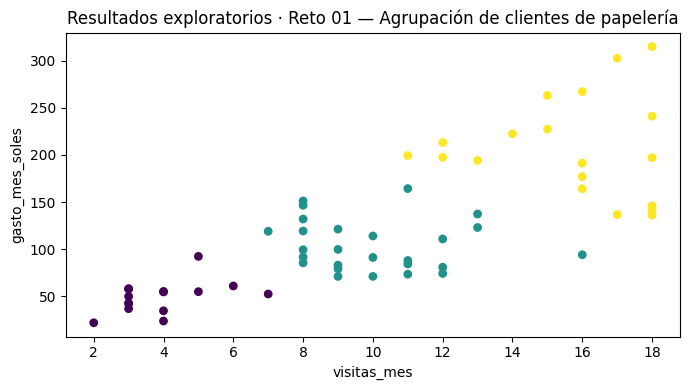

Nuevo caso de prueba: 1


In [3]:
# Entrenamiento reproducible: Reto 01 — Agrupación de clientes de papelería
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
CARACTERISTICAS = ['visitas_mes', 'gasto_mes_soles']
X = datos[CARACTERISTICAS]
escalador = StandardScaler()
X_escalada = escalador.fit_transform(X)
modelo = KMeans(n_clusters=3,random_state=42,n_init=10)
resultado = modelo.fit_predict(X_escalada)
datos['resultado'] = resultado
print('Resultados:',datos['resultado'].value_counts().sort_index().to_dict())
print('Valores medios por resultado:')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'kmeans'}, 'modelo_entrenado.joblib')
datos.to_csv('resultados.csv',index=False)
plt.figure(figsize=(7,4))
plt.scatter(datos[CARACTERISTICAS[0]],datos[CARACTERISTICAS[1]],c=resultado,cmap='viridis',s=28)
plt.xlabel(CARACTERISTICAS[0]);plt.ylabel(CARACTERISTICAS[1]);plt.title('Resultados exploratorios · '+ 'Reto 01 — Agrupación de clientes de papelería')
plt.tight_layout();plt.savefig('grafico_resultados.png',dpi=135);plt.show()
print('Nuevo caso de prueba:',modelo.predict(escalador.transform(X.iloc[[0]]))[0])


In [4]:
print('Frecuencias de resultados:')
print(datos['resultado'].value_counts().sort_index())
print('Promedios descriptivos (no atribuir calidad moral a ningún grupo):')
print(datos.groupby('resultado')[CARACTERISTICAS].mean().round(2))

Frecuencias de resultados:
resultado
0    15
1    26
2    19
Name: count, dtype: int64
Promedios descriptivos (no atribuir calidad moral a ningún grupo):
           visitas_mes  gasto_mes_soles
resultado                              
0                 3.93            49.20
1                10.00           104.04
2                15.68           207.00


In [5]:
from pathlib import Path
import joblib
joblib.dump({'modelo':modelo,'escalador':escalador,'columnas':CARACTERISTICAS,'algoritmo':'kmeans' if hasattr(modelo,'cluster_centers_') else 'isolation'}, 'modelo_entrenado.joblib')
print('Modelo y escalador exportados')

Modelo y escalador exportados


## Entrega solicitada
- Cuaderno ejecutado con explicación escrita del resultado.
- CSV original y archivo de modelo guardado.
- Carpeta Flask con `app.py`, `templates/index.html`, `static/css/estilos.css`.
- Captura del formulario con dos valores de prueba y explicación.

**Rúbrica (20 puntos):** datos y limpieza (4), entrenamiento explicado (5), interpretación correcta (4), formulario funcional (5), presentación ordenada (2).

### Respuestas cortas

1. **¿Qué buscamos?** Clientes con hábitos de compra parecidos.
2. **¿Qué usamos?** `visitas_mes` y `gasto_mes_soles`.
3. **¿Por qué escalar?** Para que el dinero no domine la distancia.
4. **¿Qué significa el grupo?** Indica semejanza, no quién compra mejor.
5. **Límite:** cambiar datos o grupos cambia los resultados.

### Interpretación de pruebas y límites del algoritmo

In [6]:
paquete=joblib.load('modelo_entrenado.joblib')
filas=datos[CARACTERISTICAS].iloc[:2].copy()
filas['prediccion']=paquete['modelo'].predict(paquete['escalador'].transform(filas))
print(filas.to_string(index=False))

 visitas_mes  gasto_mes_soles  prediccion
          12            74.21           1
           4            54.62           0


**K-Means:** Los números de grupo son identificadores arbitrarios, no puntuaciones de calidad. Se describen los promedios de cada grupo y se recuerda que cambiar el conjunto de entrenamiento puede alterar los centroides. El escalador utilizado al predecir es **exactamente el entrenado**; estos CSV son simulados.